In [10]:
!pip install ultralytics supervision

In [11]:
import cv2

video_path = "/content/testclip.mp4"
cap = cv2.VideoCapture(video_path)
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Size:", int(cap.get(3)), "x", int(cap.get(4)))

frames = []
for i in range(5):
    cap.set(cv2.CAP_PROP_POS_FRAMES, i * 150)
    ok, frame = cap.read()
    if ok:
        frames.append(frame)
print("Frames loaded:", len(frames))

FPS: 30.0
Size: 1920 x 1080
Frames loaded: 5


In [12]:
import os
video_path = "/content/testclip.mp4"

print("File exists:", os.path.exists(video_path))
print("Files in folder:", os.listdir(os.path.dirname(video_path)))

File exists: True
Files in folder: ['.config', 'yolo11x.pt', 'testclip.mp4', 'sample_data']


In [13]:
from ultralytics import YOLO
model = YOLO("yolo11x.pt")

for i, frame in enumerate(frames):
    result = model(frame, classes=[0], conf=0.2, imgsz=1280)[0]
    print(f"Frame {i}: found {len(result.boxes)} people")
    cv2.imwrite(f"/content/frame_{i}.jpg", result.plot())


0: 736x1280 34 persons, 180.4ms
Speed: 88.0ms preprocess, 180.4ms inference, 82.1ms postprocess per image at shape (1, 3, 736, 1280)
Frame 0: found 34 people

0: 736x1280 34 persons, 169.9ms
Speed: 5.6ms preprocess, 169.9ms inference, 1.6ms postprocess per image at shape (1, 3, 736, 1280)
Frame 1: found 34 people

0: 736x1280 26 persons, 168.9ms
Speed: 5.2ms preprocess, 168.9ms inference, 2.0ms postprocess per image at shape (1, 3, 736, 1280)
Frame 2: found 26 people

0: 736x1280 28 persons, 169.6ms
Speed: 5.6ms preprocess, 169.6ms inference, 1.9ms postprocess per image at shape (1, 3, 736, 1280)
Frame 3: found 28 people

0: 736x1280 28 persons, 169.2ms
Speed: 5.2ms preprocess, 169.2ms inference, 2.6ms postprocess per image at shape (1, 3, 736, 1280)
Frame 4: found 28 people


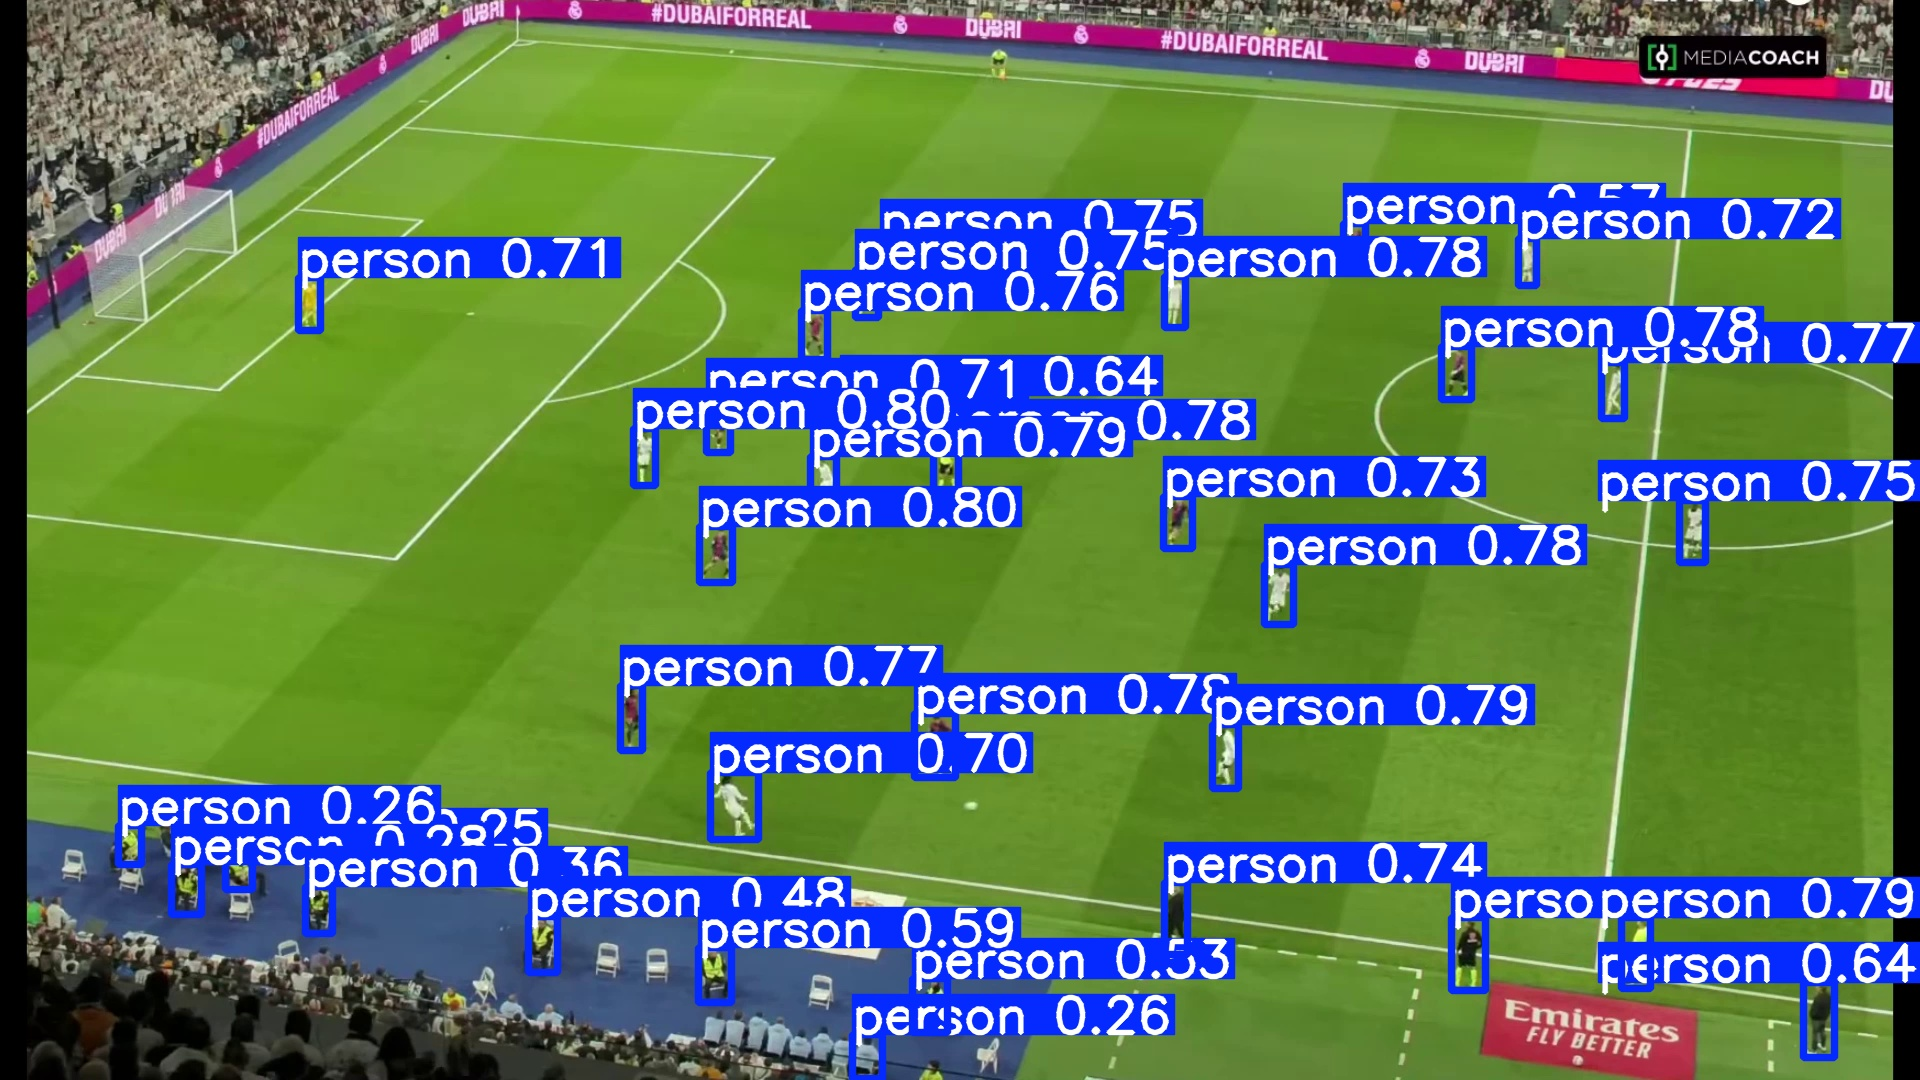

In [14]:
from IPython.display import Image, display
display(Image("/content/frame_0.jpg"))

In [15]:
import numpy as np

def on_grass(frame, box):
    x1, y1, x2, y2 = map(int, box)
    foot_y = min(y2, frame.shape[0] - 1)
    patch = frame[max(foot_y - 6, 0):foot_y + 1, max(x1, 0):x2]
    if patch.size == 0:
        return False
    hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
    return green.mean() / 255 > 0.4   # at least 40% green under the feet

for i, frame in enumerate(frames):
    result = model(frame, classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    keep = [b for b in result.boxes.xyxy.cpu().numpy() if on_grass(frame, b)]
    print(f"Frame {i}: {len(result.boxes)} -> {len(keep)} after grass filter")

Frame 0: 34 -> 26 after grass filter
Frame 1: 34 -> 29 after grass filter
Frame 2: 26 -> 25 after grass filter
Frame 3: 28 -> 26 after grass filter
Frame 4: 28 -> 27 after grass filter


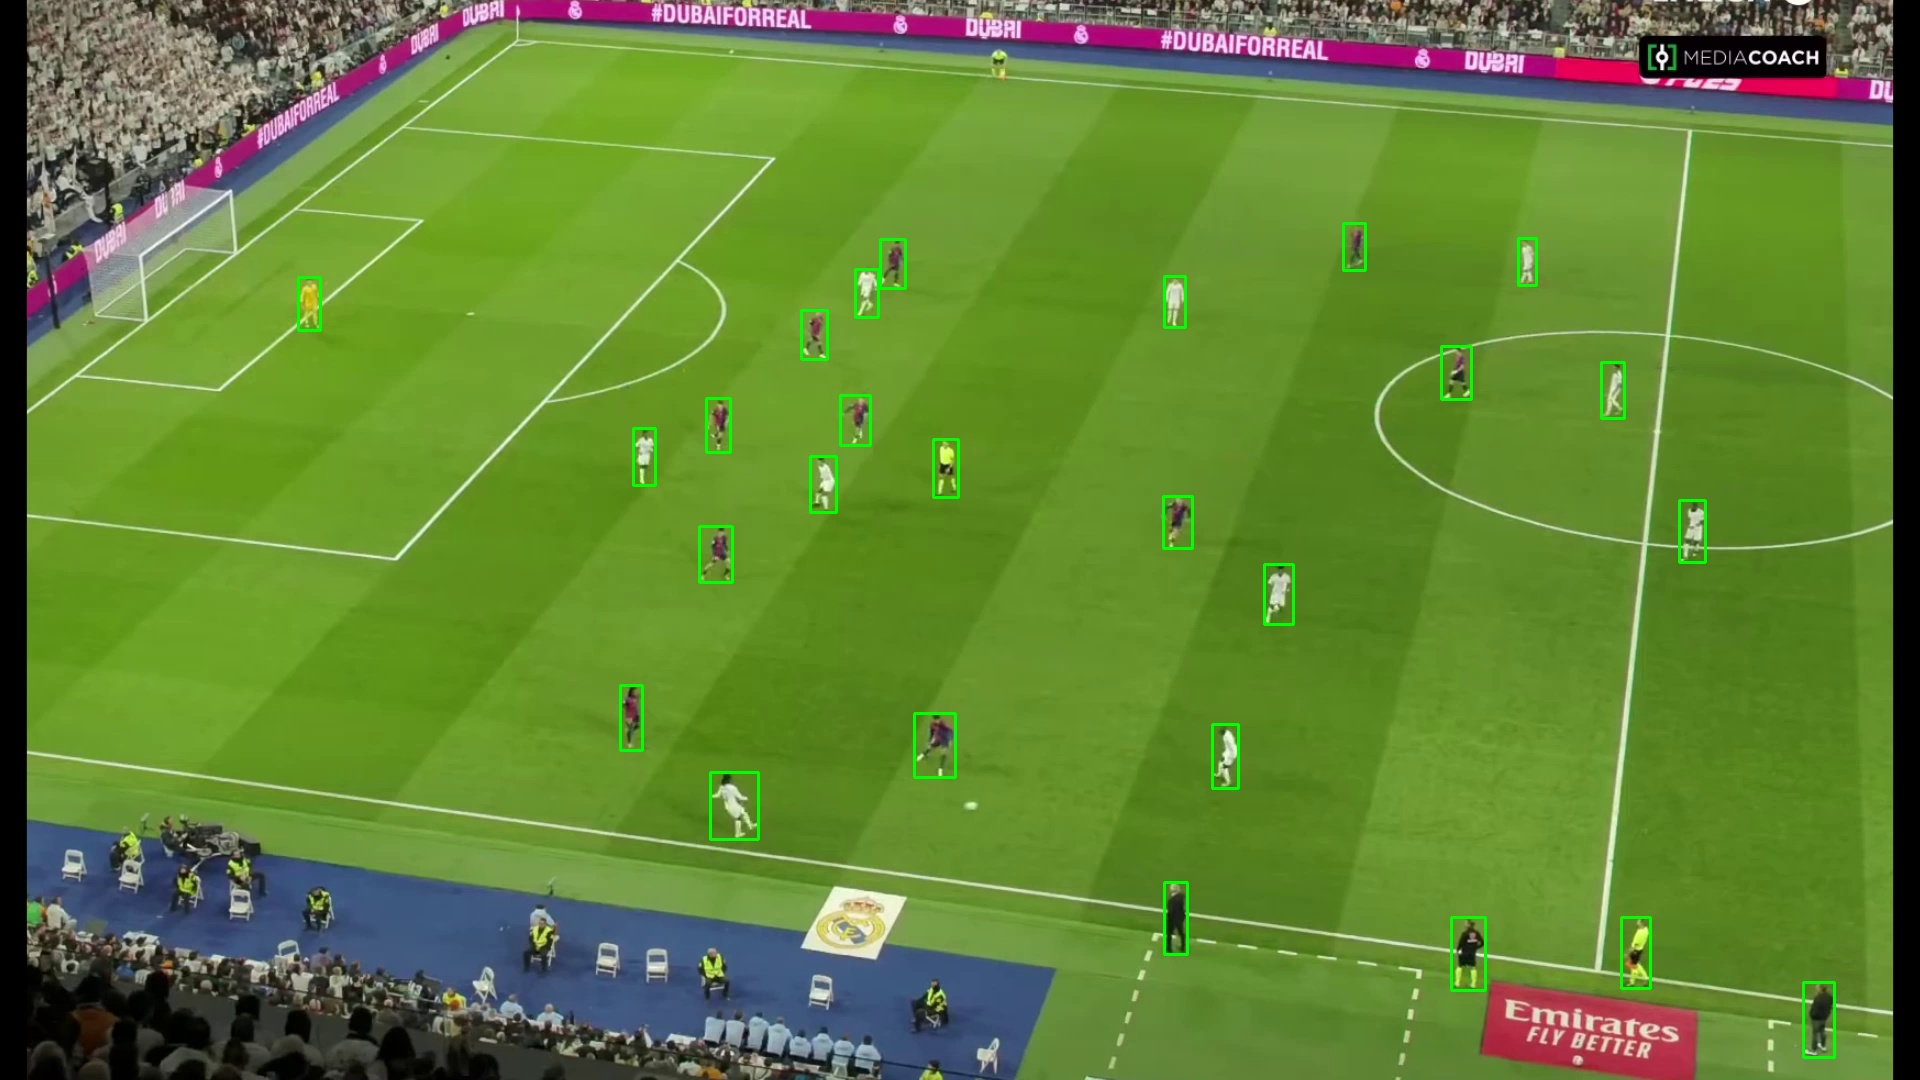

In [16]:
for i, frame in enumerate(frames):
    result = model(frame, classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    out = frame.copy()
    for b in result.boxes.xyxy.cpu().numpy():
        if on_grass(frame, b):
            x1, y1, x2, y2 = map(int, b)
            cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.imwrite(f"/content/kept_{i}.jpg", out)

display(Image("/content/kept_0.jpg"))

In [17]:
pitch_poly = np.array([
    [57, 305], [415, 35], [520, 35],
    [1456, 100], [1456, 753], [57, 568]
], dtype=np.int32)

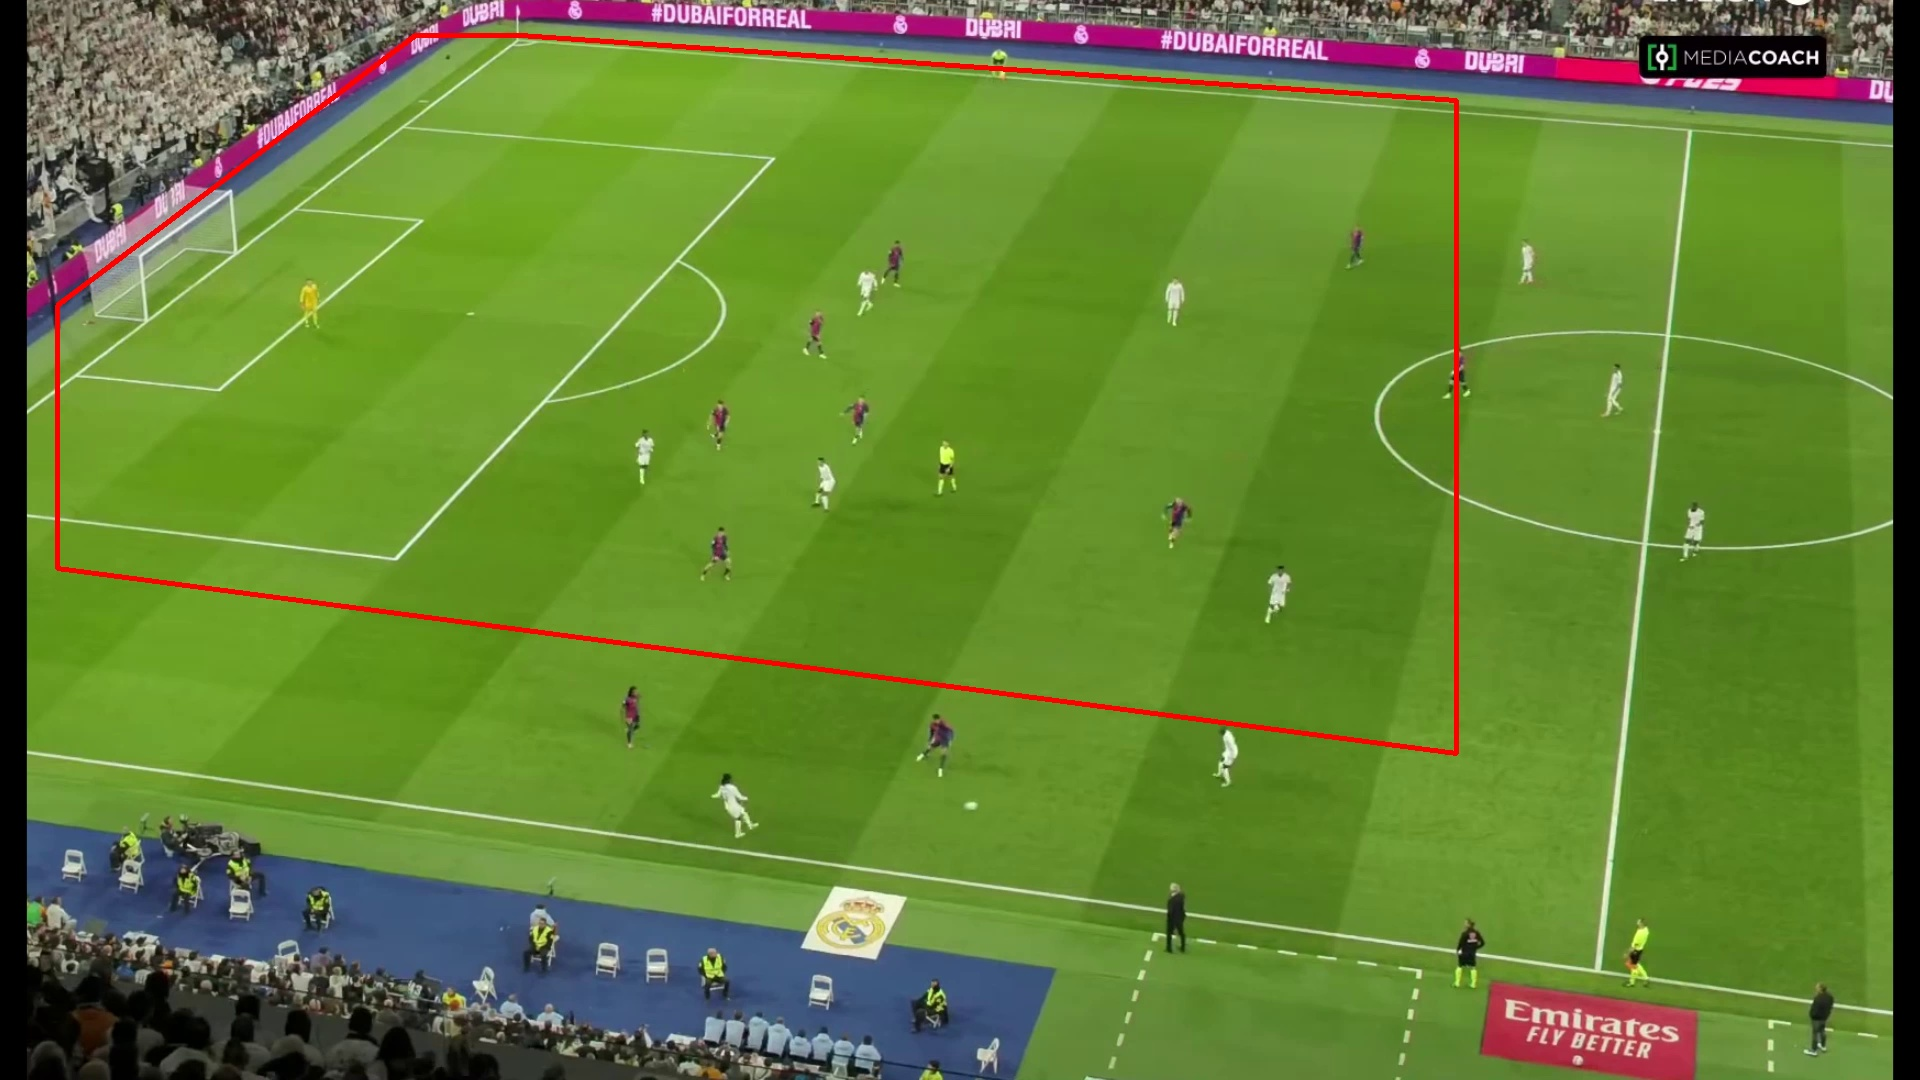

In [18]:
check = frames[0].copy()
cv2.polylines(check, [pitch_poly], True, (0, 0, 255), 3)
cv2.imwrite("/content/poly_check.jpg", check)
display(Image("/content/poly_check.jpg"))

Frame size: 1920 x 1080


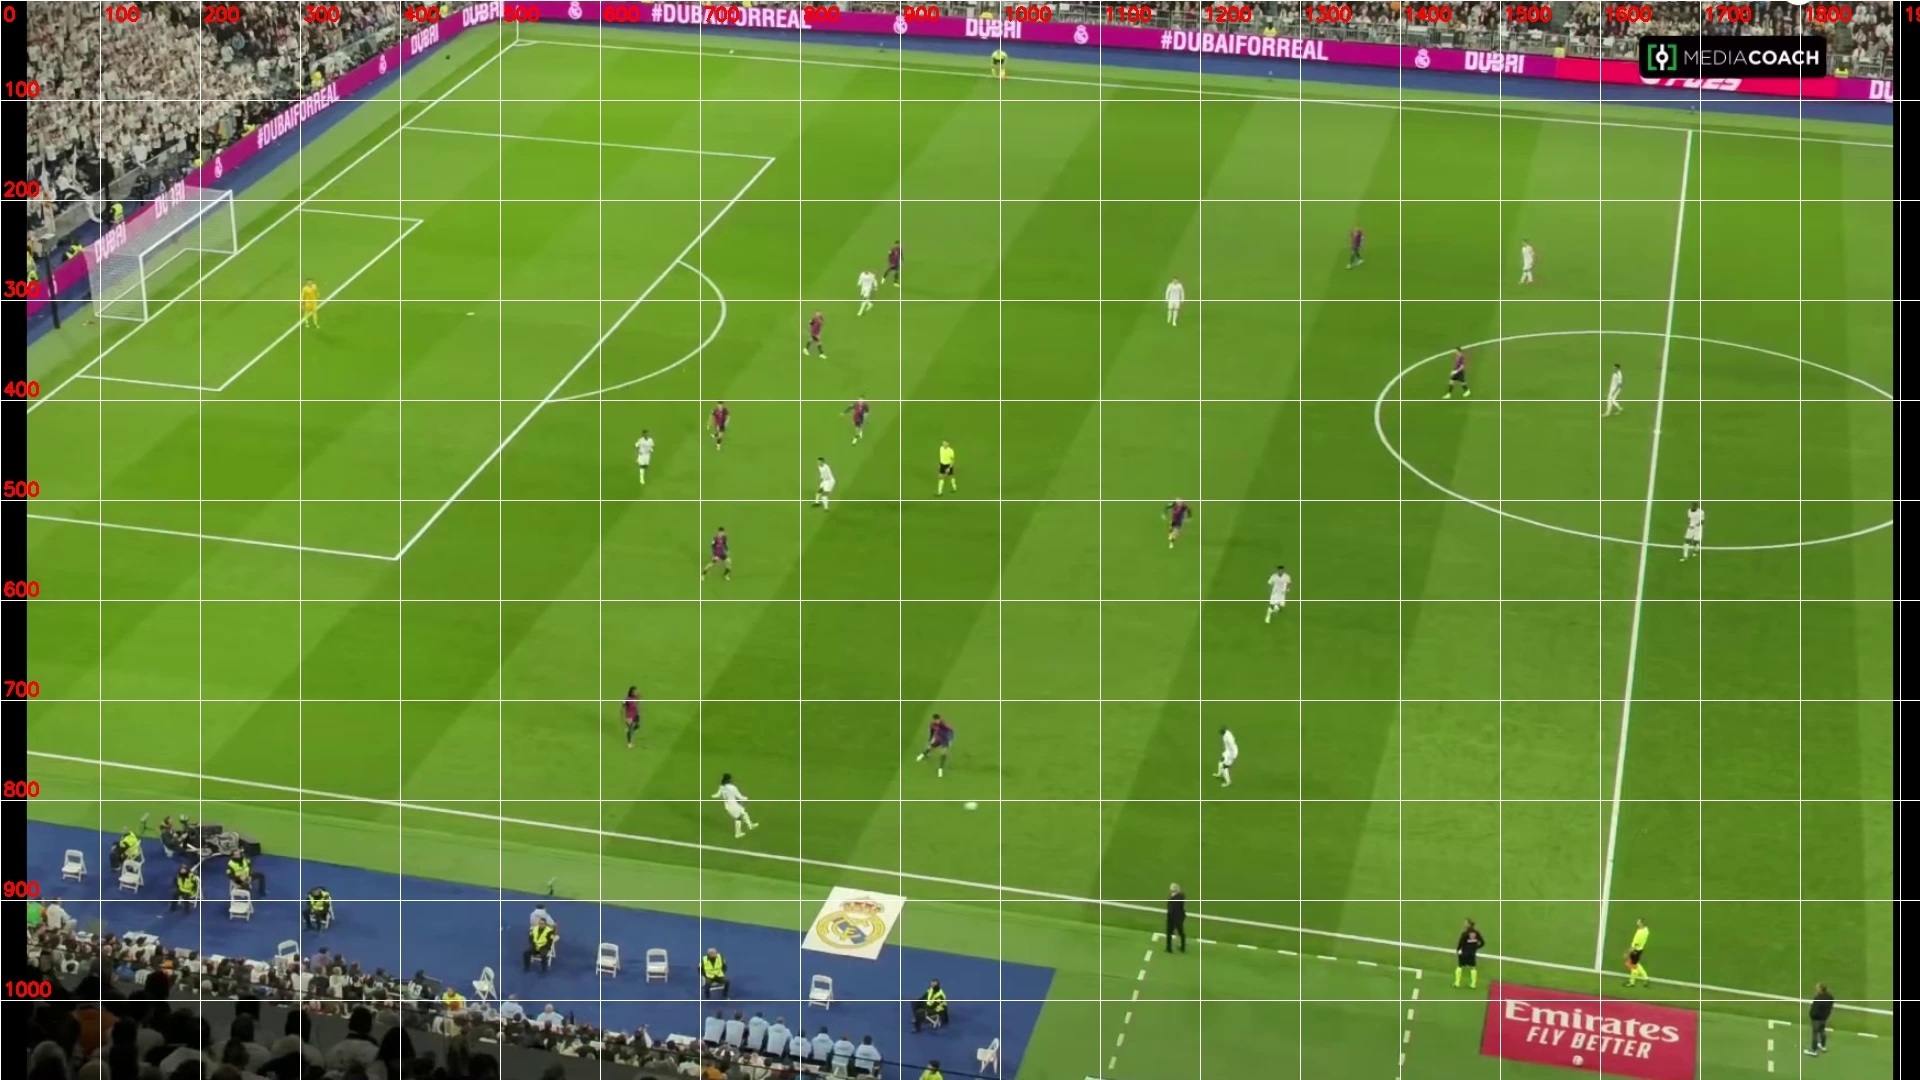

In [19]:
h, w = frames[0].shape[:2]
print("Frame size:", w, "x", h)

grid = frames[0].copy()
for x in range(0, w, 100):
    cv2.line(grid, (x, 0), (x, h), (255, 255, 255), 1)
    cv2.putText(grid, str(x), (x + 3, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
for y in range(0, h, 100):
    cv2.line(grid, (0, y), (w, y), (255, 255, 255), 1)
    cv2.putText(grid, str(y), (3, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

cv2.imwrite("/content/grid.jpg", grid)
display(Image("/content/grid.jpg"))

In [20]:
pitch_poly = np.array([
    [545, 65],      # top-left (where the far touchline meets the goal line)
    [1920, 170],    # top-right, along the far touchline
    [1920, 1030],   # bottom-right, along the near touchline
    [50, 765],      # bottom-left, along the near touchline
    [50, 425],      # left side, where the goal line meets the frame edge
], dtype=np.int32)

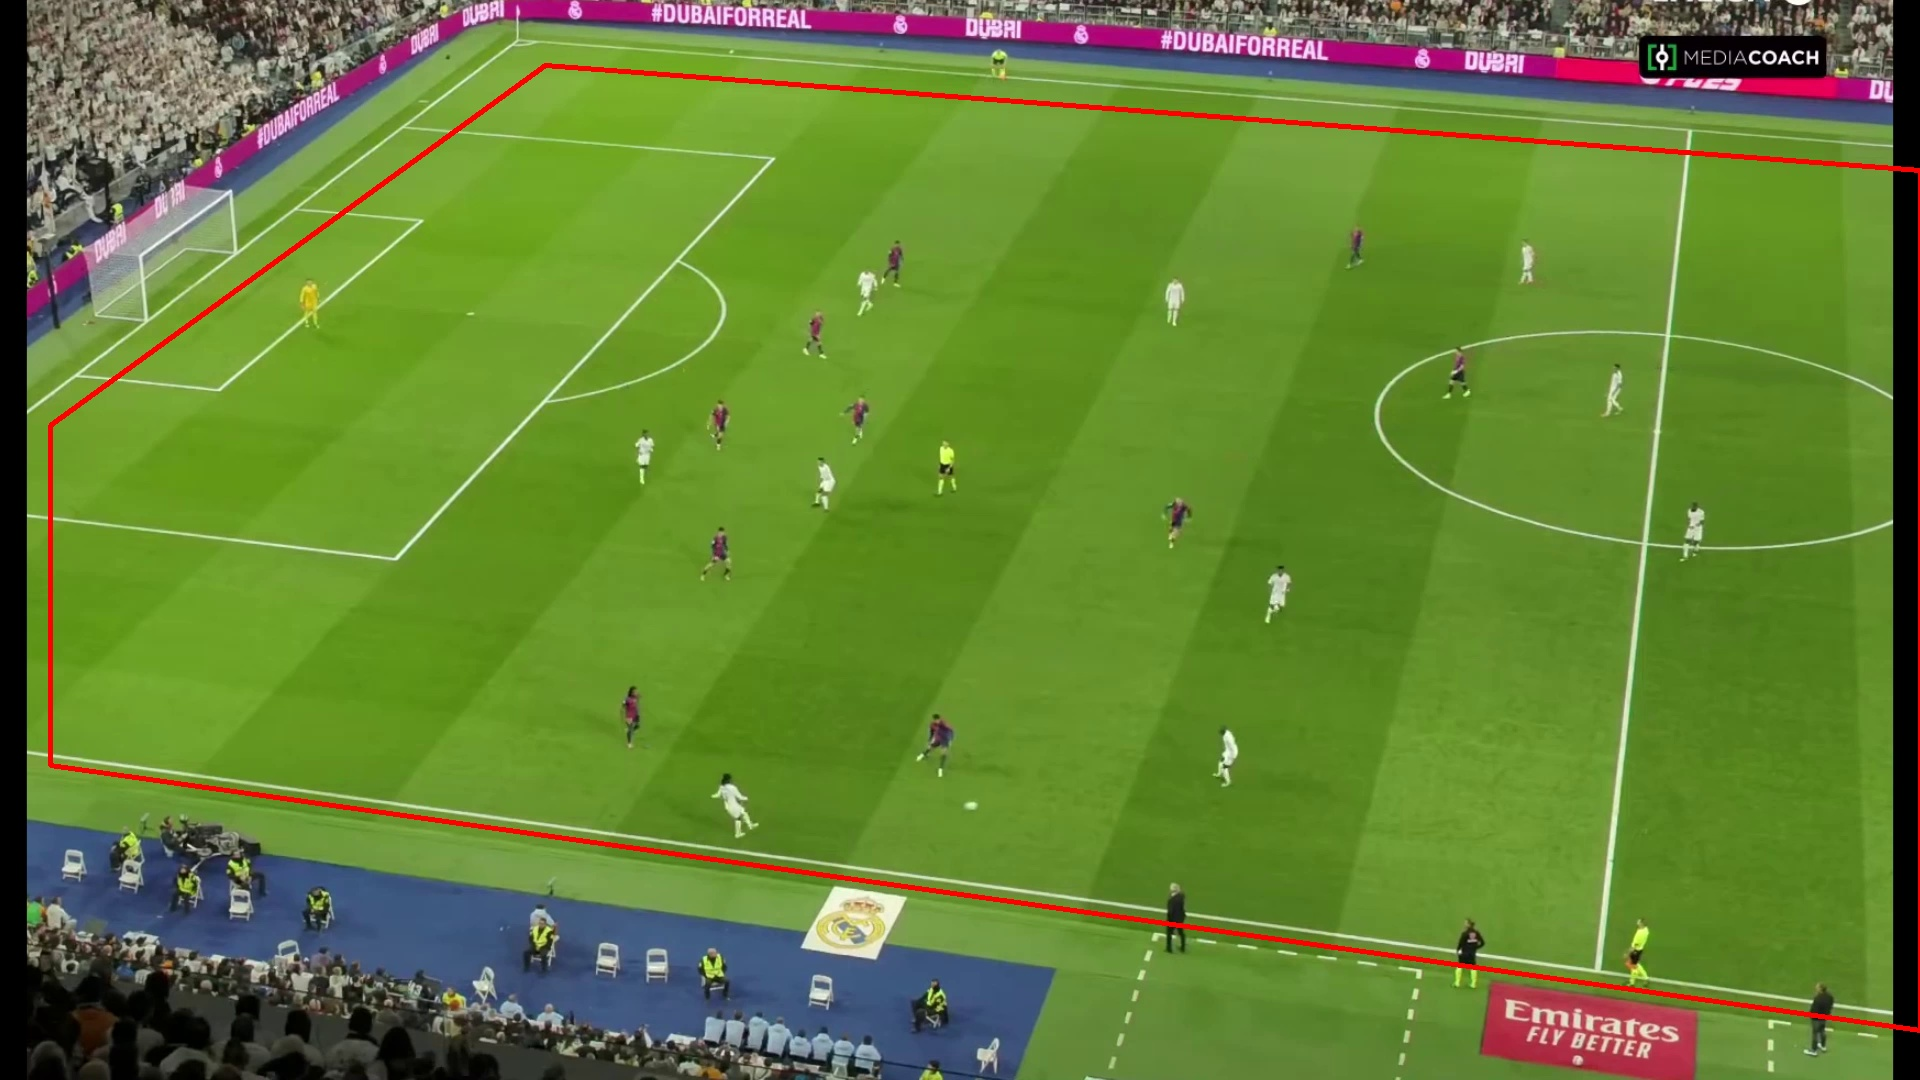

In [21]:
check = frames[0].copy()
cv2.polylines(check, [pitch_poly], True, (0, 0, 255), 4)
cv2.imwrite("/content/poly_check.jpg", check)
display(Image("/content/poly_check.jpg"))

In [24]:
import cv2
import numpy as np
from IPython.display import Image, display

def pitch_mask(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    green = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
    green = cv2.morphologyEx(green, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    cnts, _ = cv2.findContours(green, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(green)
    if cnts:
        biggest = max(cnts, key=cv2.contourArea)
        cv2.drawContours(mask, [biggest], -1, 255, -1)
    return mask

def in_pitch_dynamic(mask, box):
    x1, y1, x2, y2 = box
    fx = int(min(max((x1 + x2) / 2, 0), mask.shape[1] - 1))
    fy = int(min(max(y2, 0), mask.shape[0] - 1))
    return mask[fy, fx] > 0

def torso_color(frame, box):
    x1, y1, x2, y2 = map(int, box)
    h, w = y2 - y1, x2 - x1
    crop = frame[y1 + int(0.2*h): y1 + int(0.55*h), x1 + int(0.2*w): x2 - int(0.2*w)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    notgreen = ~((hsv[..., 0] > 35) & (hsv[..., 0] < 85) & (hsv[..., 1] > 40))
    pix = crop[notgreen]
    if len(pix) < 5:
        pix = crop.reshape(-1, 3)
    lab = cv2.cvtColor(pix.reshape(-1, 1, 3), cv2.COLOR_BGR2LAB).reshape(-1, 3)
    return np.median(lab, axis=0)

In [25]:
for i, frame in enumerate(frames):
    m = pitch_mask(frame)
    result = model(frame, classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    keep = [b for b in result.boxes.xyxy.cpu().numpy() if in_pitch_dynamic(m, b)]
    print(f"Frame {i}: {len(result.boxes)} -> {len(keep)}")

Frame 0: 34 -> 28
Frame 1: 34 -> 28
Frame 2: 26 -> 25
Frame 3: 28 -> 26
Frame 4: 28 -> 26


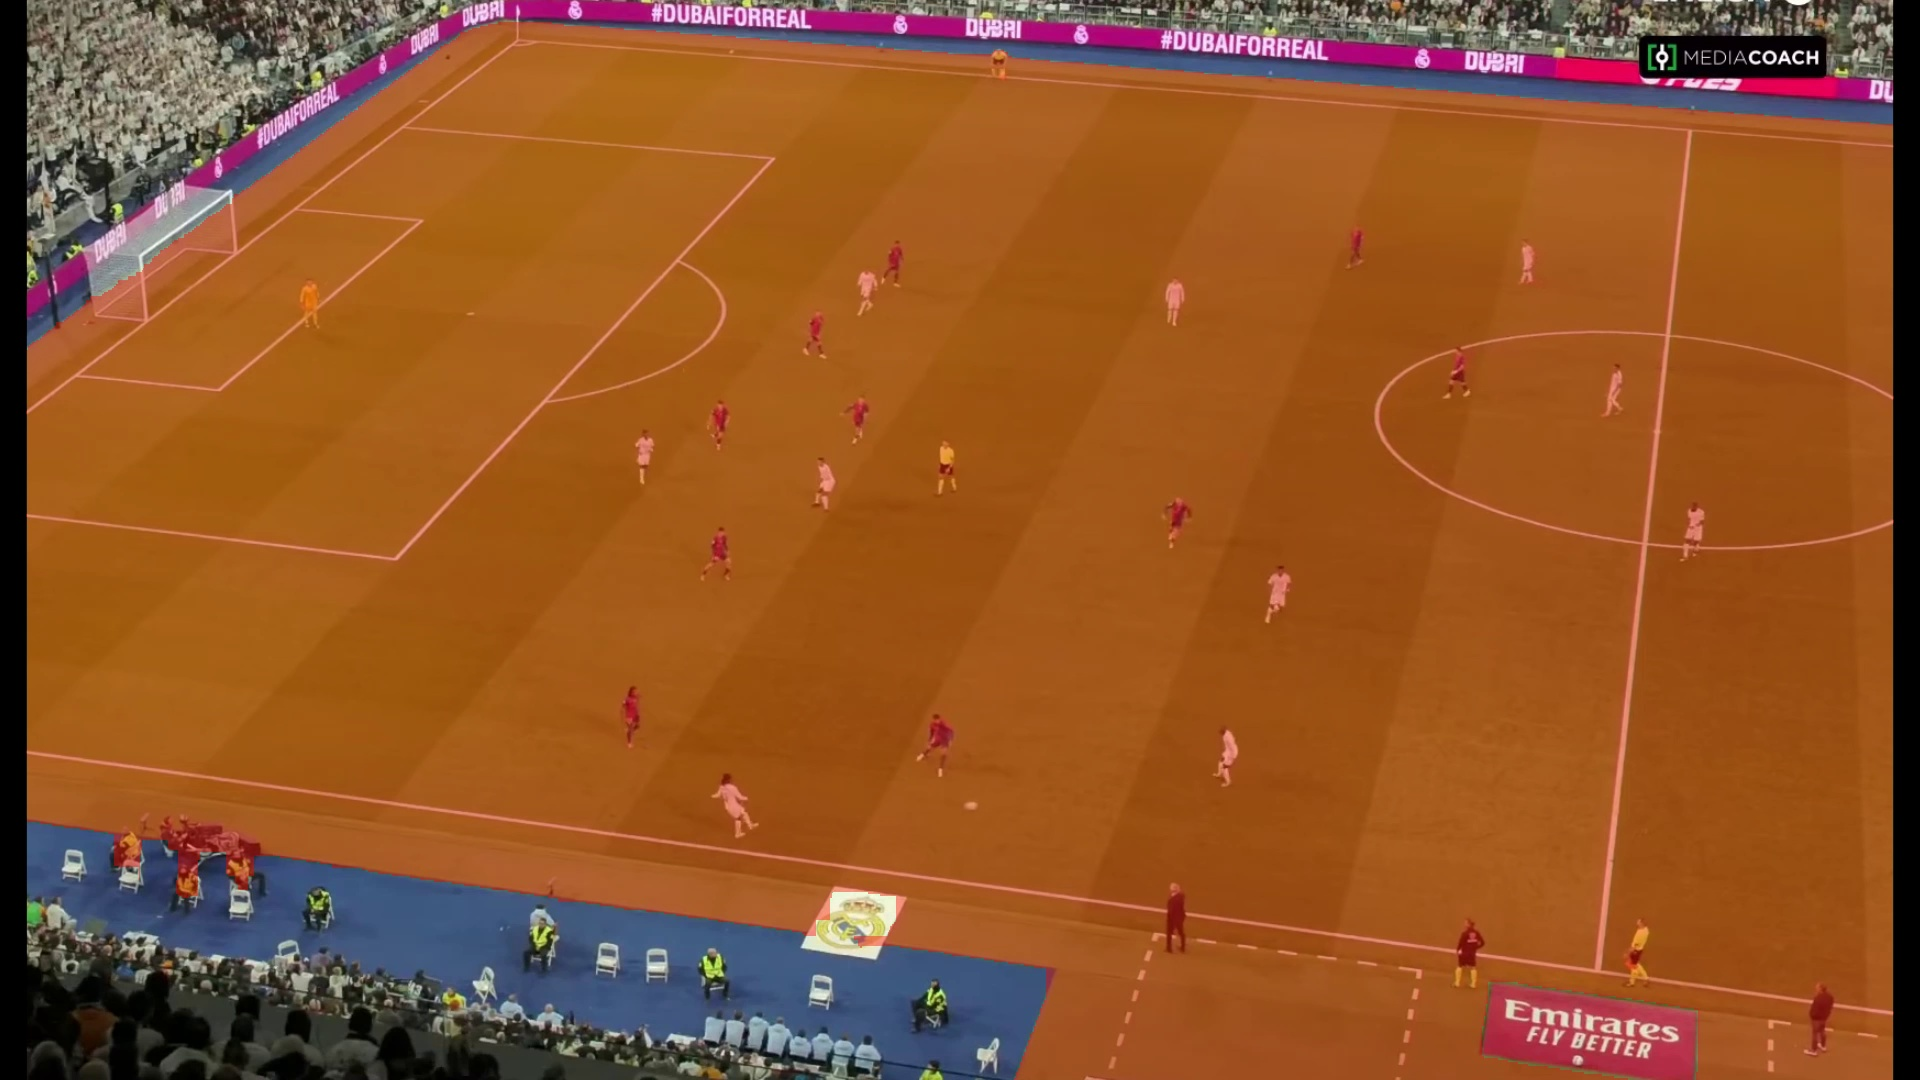

In [26]:
m = pitch_mask(frames[0])
overlay = frames[0].copy()
overlay[m > 0] = (0.6 * overlay[m > 0] + 0.4 * np.array([0, 0, 255])).astype(np.uint8)
cv2.imwrite("/content/mask_check.jpg", overlay)
display(Image("/content/mask_check.jpg"))

In [27]:
for i, frame in enumerate(frames):
    m = pitch_mask(frame)
    result = model(frame, classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    keep = [b for b in result.boxes.xyxy.cpu().numpy() if in_pitch_dynamic(m, b)]
    print(f"Frame {i}: {len(result.boxes)} -> {len(keep)}")

Frame 0: 34 -> 28
Frame 1: 34 -> 28
Frame 2: 26 -> 25
Frame 3: 28 -> 26
Frame 4: 28 -> 26


In [28]:
def torso_color(frame, box):
    x1, y1, x2, y2 = map(int, box)
    h, w = y2 - y1, x2 - x1
    crop = frame[y1 + int(0.2*h): y1 + int(0.55*h), x1 + int(0.2*w): x2 - int(0.2*w)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    notgreen = ~((hsv[..., 0] > 35) & (hsv[..., 0] < 85) & (hsv[..., 1] > 40))
    pix = crop[notgreen]
    if len(pix) < 5:
        pix = crop.reshape(-1, 3)
    lab = cv2.cvtColor(pix.reshape(-1, 1, 3), cv2.COLOR_BGR2LAB).reshape(-1, 3)
    return np.median(lab, axis=0)

In [29]:
from sklearn.cluster import KMeans

records = []
for i, frame in enumerate(frames):
    m = pitch_mask(frame)
    result = model(frame, classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    for b in result.boxes.xyxy.cpu().numpy():
        if in_pitch_dynamic(m, b):
            c = torso_color(frame, b)
            if c is not None:
                records.append((i, b, c))

colors = np.array([r[2] for r in records])
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(colors)
labels = kmeans.labels_
print("Players per cluster:", np.bincount(labels))

Players per cluster: [44 49 27 13]


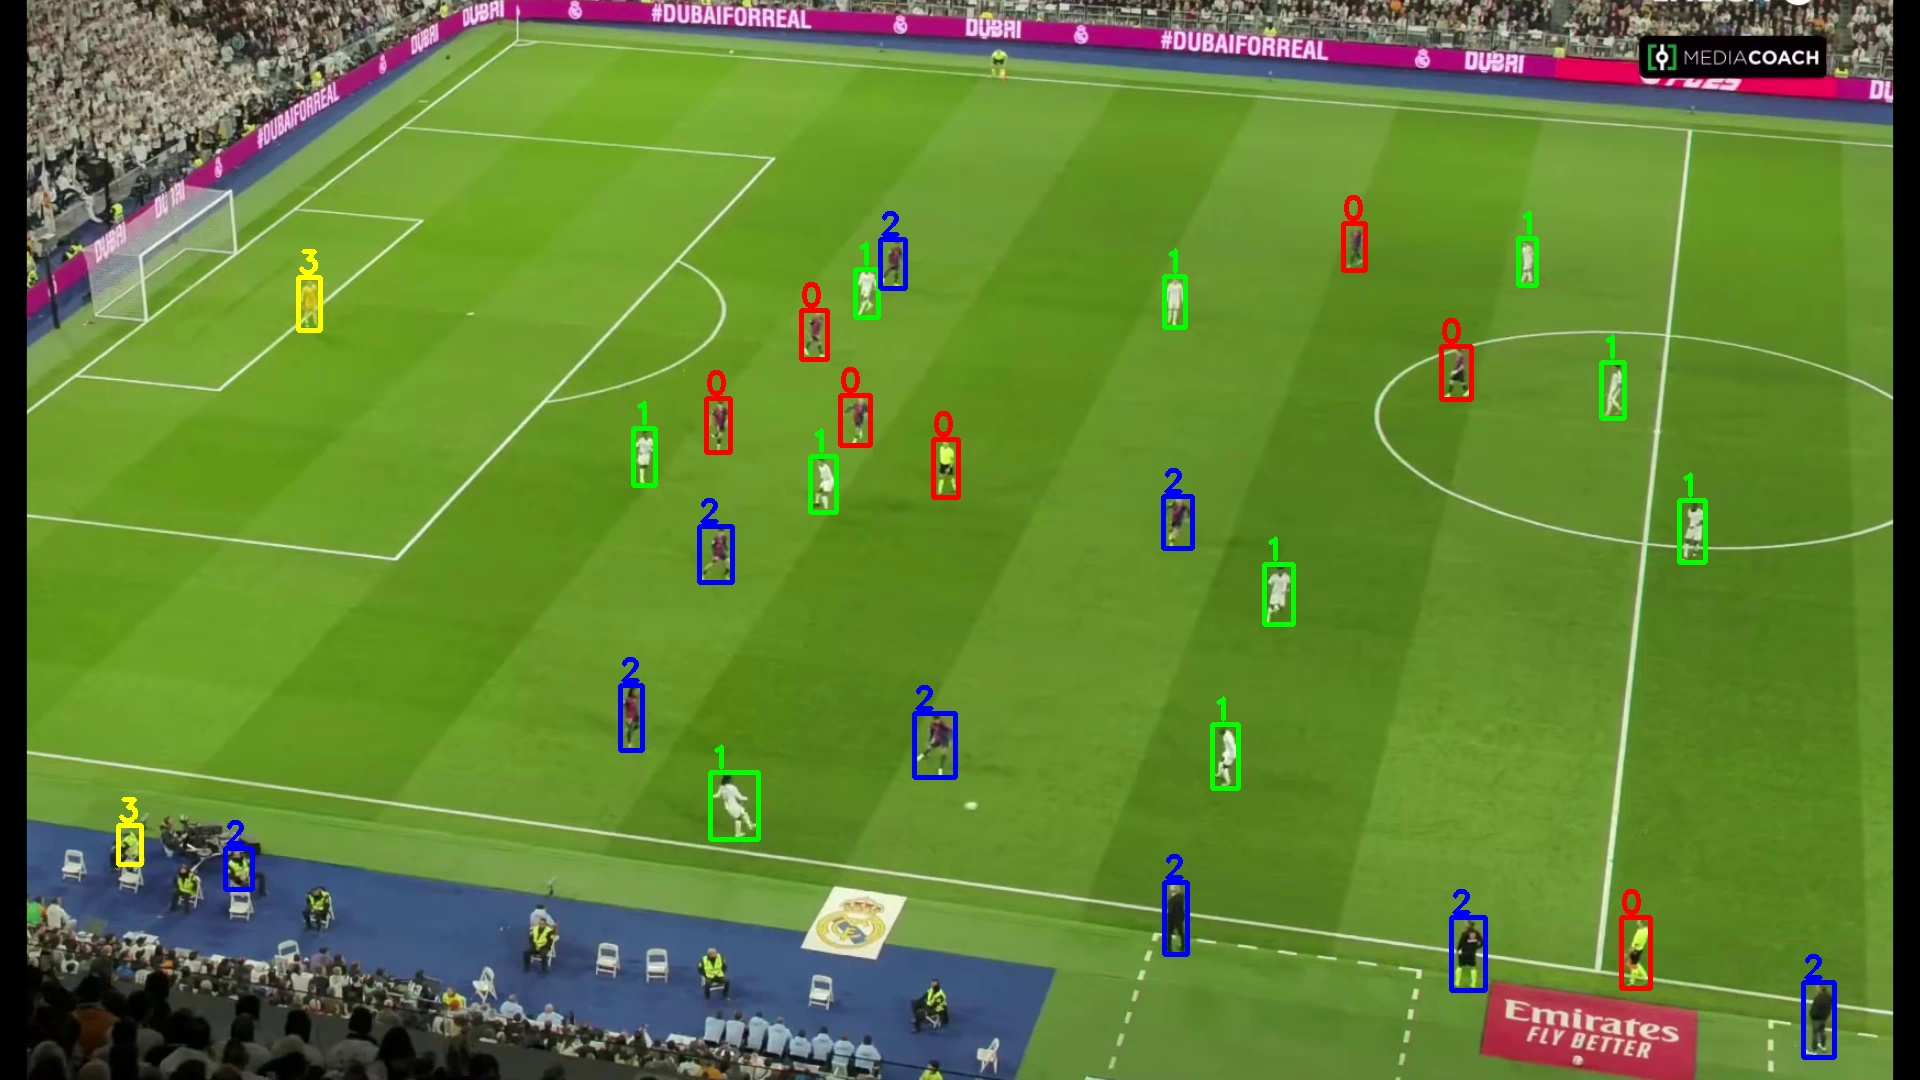

In [30]:
palette = [(0, 0, 255), (0, 255, 0), (255, 0, 0), (0, 255, 255)]
out = frames[0].copy()
for (i, b, c), lab in zip(records, labels):
    if i == 0:
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(out, (x1, y1), (x2, y2), palette[lab], 3)
        cv2.putText(out, str(lab), (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 1, palette[lab], 3)
cv2.imwrite("/content/clusters.jpg", out)
display(Image("/content/clusters.jpg"))

In [31]:
kmeans = KMeans(n_clusters=6, n_init=10, random_state=0).fit(colors)
labels = kmeans.labels_
print("Players per cluster:", np.bincount(labels))

Players per cluster: [11 17 49 34 11 11]


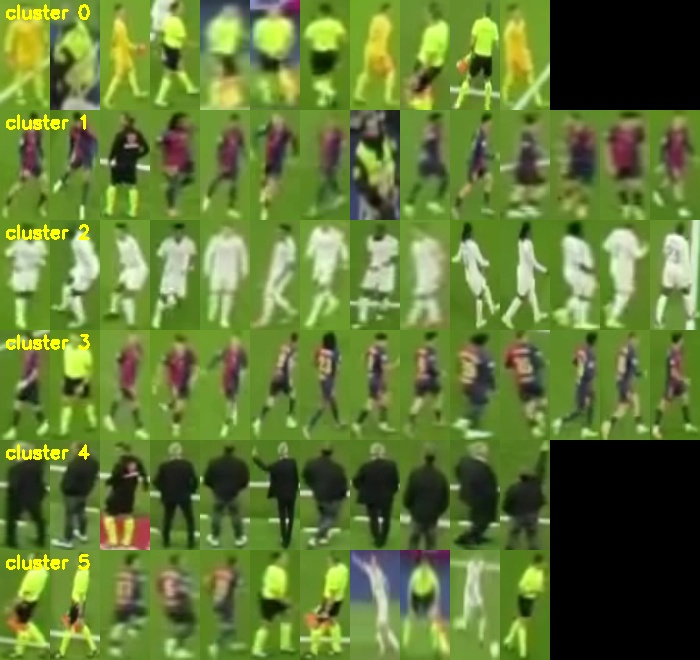

In [32]:
def crop_of(i, b):
    x1, y1, x2, y2 = map(int, b)
    c = frames[i][max(y1, 0):y2, max(x1, 0):x2]
    return cv2.resize(c, (50, 110))

rows = []
for k in range(6):
    crops = [crop_of(i, b) for (i, b, c), l in zip(records, labels) if l == k][:14]
    while len(crops) < 14:
        crops.append(np.zeros((110, 50, 3), np.uint8))
    row = np.hstack(crops)
    cv2.putText(row, f"cluster {k}", (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
    rows.append(row)

cv2.imwrite("/content/sheet.jpg", np.vstack(rows))
display(Image("/content/sheet.jpg"))

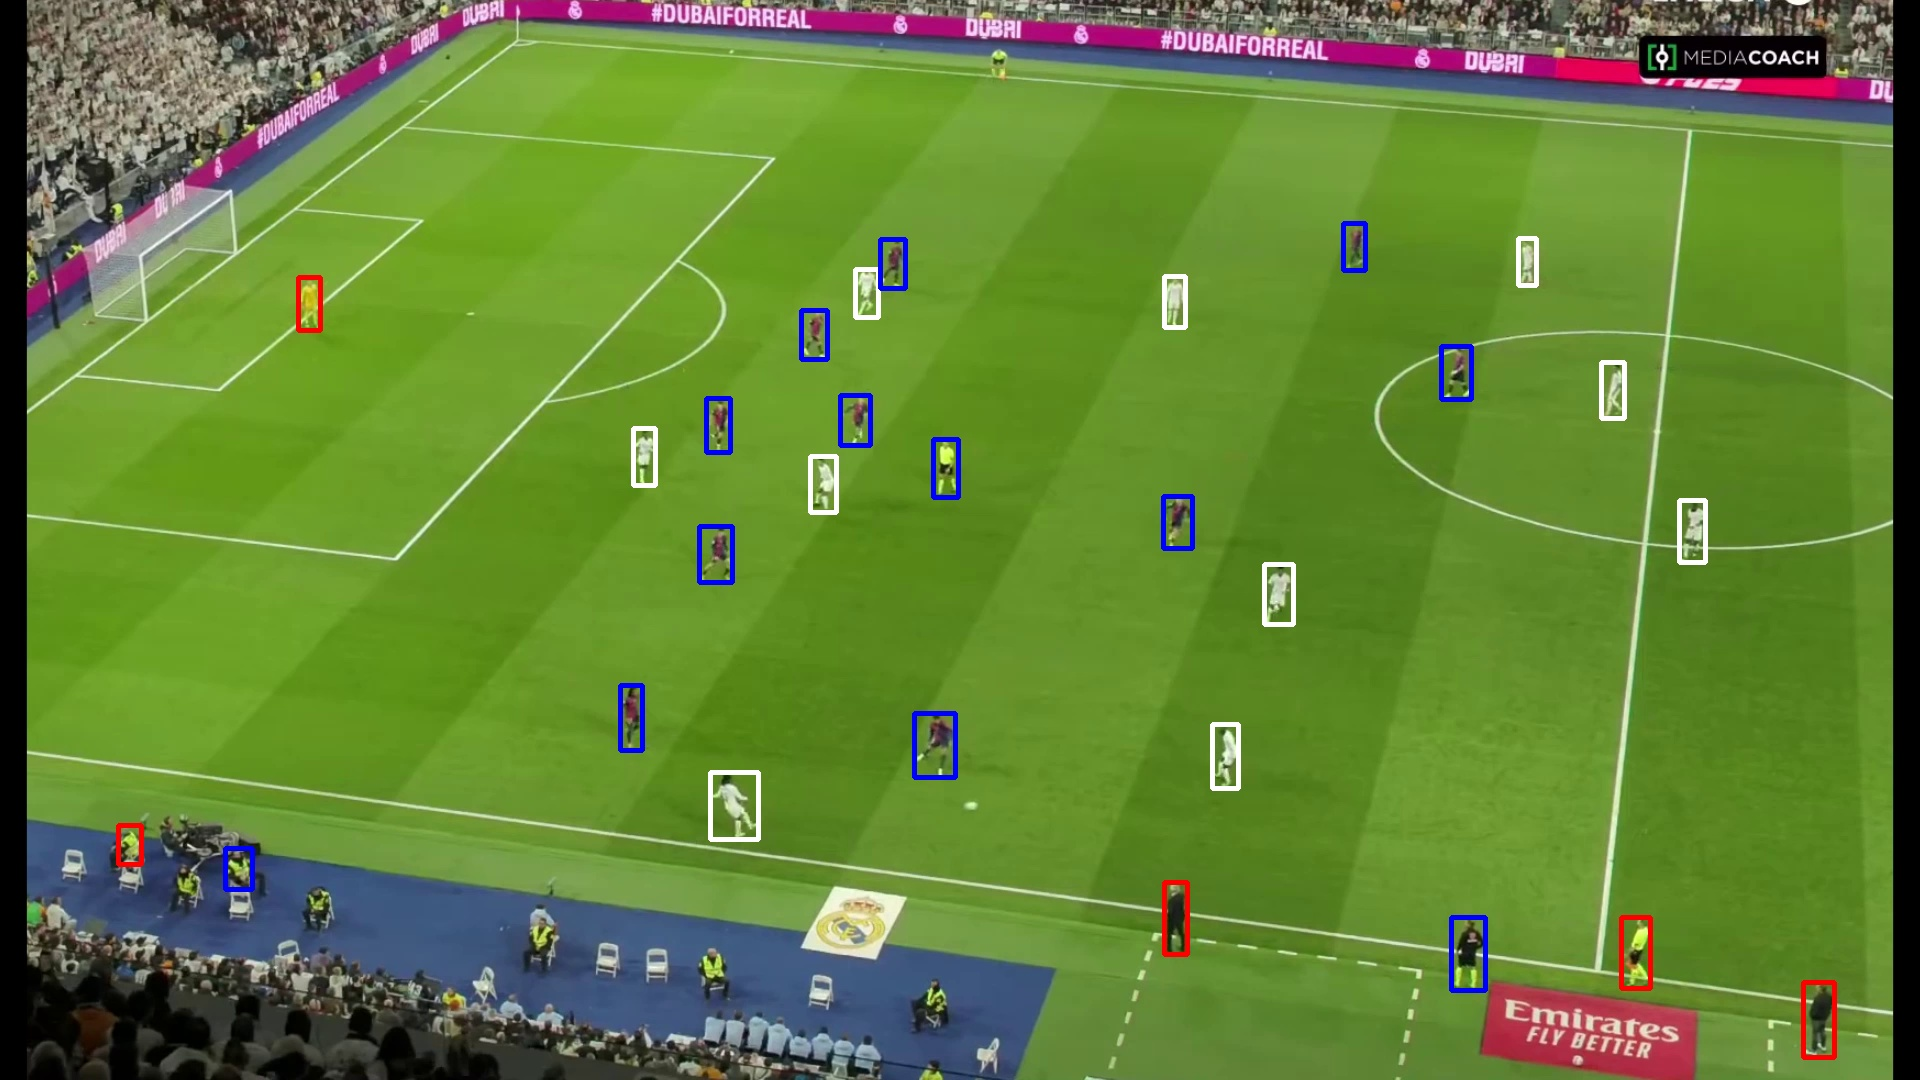

Counter({'barca': 51, 'madrid': 49, 'other': 33})


In [35]:
team_map = {0: "other", 1: "barca", 2: "madrid", 3: "barca", 4: "other", 5: "other"}

team_colors = {"barca": (255, 0, 0), "madrid": (255, 255, 255), "other": (0, 0, 255)}
out = frames[0].copy()
for (i, b, c), lab in zip(records, labels):
    if i == 0:
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(out, (x1, y1), (x2, y2), team_colors[team_map[lab]], 3)
cv2.imwrite("/content/teams.jpg", out)
display(Image("/content/teams.jpg"))

from collections import Counter
print(Counter(team_map[l] for l in labels))

In [37]:
import supervision as sv
from collections import defaultdict, Counter

video_path = "/content/testclip.mp4"
START, N = 0, 300

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, START)

tracks = {}
votes = defaultdict(list)

for f in range(N):
    ok, frame = cap.read()
    if not ok:
        break
    m = pitch_mask(frame)
    res = model.track(frame, persist=True, tracker="bytetrack.yaml",
                      classes=[0], conf=0.2, imgsz=1280, verbose=False)[0]
    tracks[f] = []
    if res.boxes.id is None:
        continue
    for b, tid in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.id.cpu().numpy().astype(int)):
        if not in_pitch_dynamic(m, b):
            continue
        c = torso_color(frame, b)
        if c is None:
            continue
        team = team_map[int(kmeans.predict(c.reshape(1, -1))[0])]
        votes[tid].append(team)
        tracks[f].append((tid, b))

print("Frames tracked:", len(tracks), "| unique IDs:", len(votes))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 1.44s
Prepared 1 package in 23ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 1.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Frames tracked: 300 | unique IDs: 41


In [38]:
id_team = {}
for tid, v in votes.items():
    if len(v) >= 15:                         # ignore IDs seen in fewer than 15 frames
        id_team[tid] = Counter(v).most_common(1)[0][0]

print(Counter(id_team.values()))
print("IDs dropped as too short-lived:", len(votes) - len(id_team))

Counter({'barca': 15, 'madrid': 11, 'other': 7})
IDs dropped as too short-lived: 8


In [39]:
colors = {"barca": (255, 0, 0), "madrid": (255, 255, 255), "other": (0, 0, 255)}
W, H = int(cap.get(3)), int(cap.get(4))
fps = cap.get(cv2.CAP_PROP_FPS) or 30
out = cv2.VideoWriter("/content/tracked_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

cap.set(cv2.CAP_PROP_POS_FRAMES, START)
for f in range(len(tracks)):
    ok, frame = cap.read()
    if not ok:
        break
    for tid, b in tracks[f]:
        if tid not in id_team:
            continue
        x1, y1, x2, y2 = map(int, b)
        col = colors[id_team[tid]]
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
        cv2.putText(frame, str(tid), (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
    out.write(frame)
out.release()

!ffmpeg -y -i /content/tracked_raw.mp4 -c:v libx264 /content/tracked.mp4 -loglevel error
print("Saved /content/tracked.mp4")

Saved /content/tracked.mp4


In [40]:
force_other = {58, 44}
for tid in force_other:
    if tid in id_team:
        id_team[tid] = "other"

print(Counter(id_team.values()))

Counter({'barca': 13, 'madrid': 11, 'other': 9})


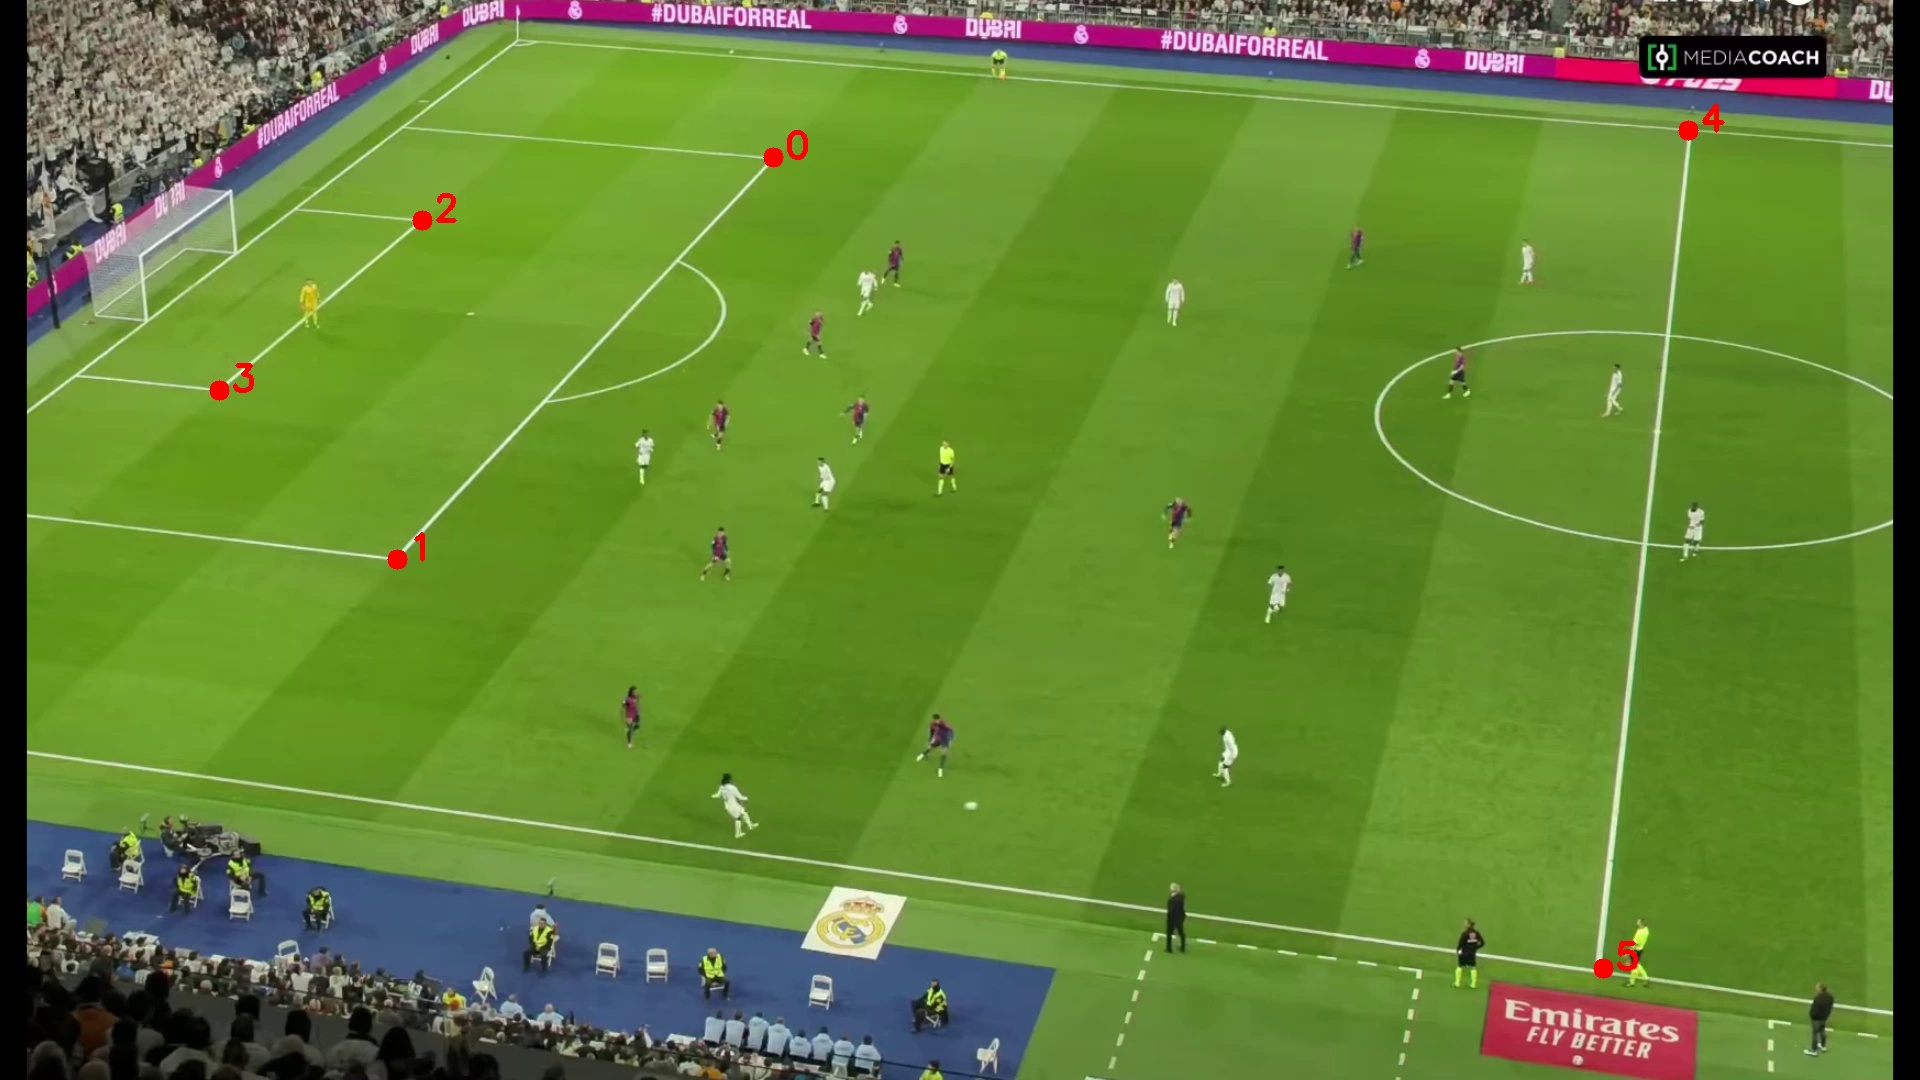

In [41]:
img_pts = np.array([
    [773, 157],    # far corner of the penalty box
    [397, 559],    # near corner of the penalty box
    [422, 220],    # far corner of the 6-yard box
    [219, 390],    # near corner of the 6-yard box
    [1688, 130],   # halfway line meets the far touchline
    [1603, 968],   # halfway line meets the near touchline
], dtype=np.float32)

pitch_pts = np.array([
    [16.5, 13.84],
    [16.5, 54.16],
    [5.5, 24.84],
    [5.5, 43.16],
    [52.5, 0.0],
    [52.5, 68.0],
], dtype=np.float32)

check = frames[0].copy()
for k, (x, y) in enumerate(img_pts):
    cv2.circle(check, (int(x), int(y)), 10, (0, 0, 255), -1)
    cv2.putText(check, str(k), (int(x) + 12, int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
cv2.imwrite("/content/landmarks.jpg", check)
display(Image("/content/landmarks.jpg"))

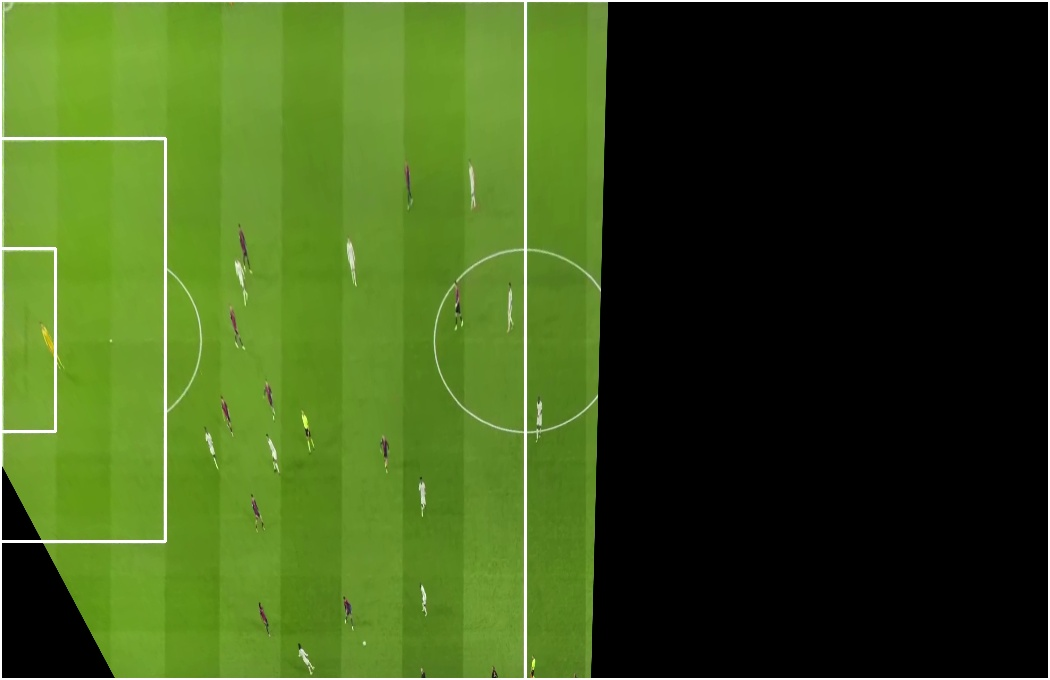

In [42]:
H, _ = cv2.findHomography(img_pts, pitch_pts, cv2.RANSAC)

S = 10   # pixels per metre in the preview
M = np.array([[S, 0, 0], [0, S, 0], [0, 0, 1]]) @ H
topdown = cv2.warpPerspective(frames[0], M, (105 * S, 68 * S))

# draw the pitch outline, halfway line, boxes
cv2.rectangle(topdown, (0, 0), (105 * S - 1, 68 * S - 1), (255, 255, 255), 2)
cv2.line(topdown, (int(52.5 * S), 0), (int(52.5 * S), 68 * S), (255, 255, 255), 2)
cv2.rectangle(topdown, (0, int(13.84 * S)), (int(16.5 * S), int(54.16 * S)), (255, 255, 255), 2)
cv2.rectangle(topdown, (0, int(24.84 * S)), (int(5.5 * S), int(43.16 * S)), (255, 255, 255), 2)
cv2.imwrite("/content/topdown.jpg", topdown)
display(Image("/content/topdown.jpg"))

In [43]:
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, START)

Hs = []                      # Hs[f] maps frame f pixels to pitch metres
Hcur = H.copy()
prev_gray, prev_mask = None, None

for f in range(N):
    ok, frame = cap.read()
    if not ok:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    mask = pitch_mask(frame)

    if f > 0:
        # ignore people in the previous frame
        m = prev_mask.copy()
        for tid, b in tracks.get(f - 1, []):
            x1, y1, x2, y2 = map(int, b)
            cv2.rectangle(m, (x1 - 8, y1 - 8), (x2 + 8, y2 + 8), 0, -1)

        p0 = cv2.goodFeaturesToTrack(prev_gray, maxCorners=800, qualityLevel=0.01,
                                     minDistance=10, mask=m)
        P = np.eye(3)
        if p0 is not None and len(p0) >= 8:
            p1, st, _ = cv2.calcOpticalFlowPyrLK(prev_gray, gray, p0, None)
            good = st.ravel() == 1
            if good.sum() >= 8:
                Pm, _ = cv2.findHomography(p1[good], p0[good], cv2.RANSAC, 3.0)
                if Pm is not None:
                    P = Pm                      # maps frame f to frame f-1
        Hcur = Hcur @ P
    Hs.append(Hcur.copy())
    prev_gray, prev_mask = gray, mask

print("Homographies computed:", len(Hs))

Homographies computed: 300


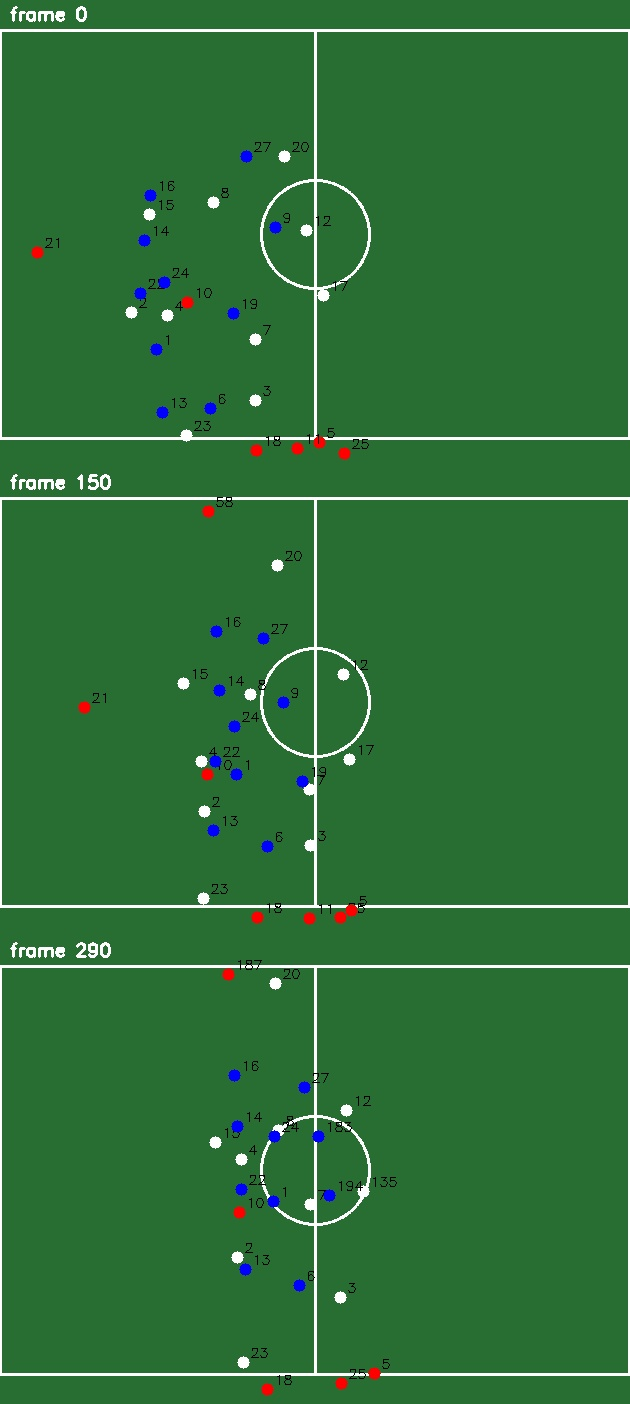

In [44]:
S = 6   # pixels per metre
colors = {"barca": (255, 0, 0), "madrid": (255, 255, 255), "other": (0, 0, 255)}

def draw_minimap(f):
    img = np.zeros((68 * S + 60, 105 * S, 3), np.uint8)
    img[:] = (50, 110, 40)
    off = 30                                    # margin so off-pitch staff are visible
    cv2.rectangle(img, (0, off), (105 * S - 1, off + 68 * S), (255, 255, 255), 2)
    cv2.line(img, (int(52.5 * S), off), (int(52.5 * S), off + 68 * S), (255, 255, 255), 2)
    cv2.circle(img, (int(52.5 * S), off + 34 * S), int(9.15 * S), (255, 255, 255), 2)
    for tid, b in tracks[f]:
        if tid not in id_team:
            continue
        foot = np.array([[[(b[0] + b[2]) / 2, b[3]]]], np.float32)
        px, py = cv2.perspectiveTransform(foot, Hs[f])[0, 0]
        x, y = int(px * S), int(py * S) + off
        if 0 <= x < img.shape[1] and 0 <= y < img.shape[0]:
            cv2.circle(img, (x, y), 6, colors[id_team[tid]], -1)
            cv2.putText(img, str(tid), (x + 7, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1)
    cv2.putText(img, f"frame {f}", (10, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    return img

sheet = np.vstack([draw_minimap(f) for f in [0, 150, 290]])
cv2.imwrite("/content/minimap.jpg", sheet)
display(Image("/content/minimap.jpg"))

In [45]:
traj = defaultdict(dict)   # id -> {frame: (x, y) in metres}
for f in range(len(Hs)):
    for tid, b in tracks[f]:
        foot = np.array([[[(b[0] + b[2]) / 2, b[3]]]], np.float32)
        x, y = cv2.perspectiveTransform(foot, Hs[f])[0, 0]
        traj[tid][f] = (float(x), float(y))

print("IDs with paths:", len(traj))

IDs with paths: 41


In [46]:
def span(t):
    fr = sorted(traj[t])
    return fr[0], fr[-1]

ids = [t for t in id_team if id_team[t] != "other" and t in traj]
ids.sort(key=lambda t: span(t)[0])          # order by when they first appear

merge, used = {}, set()                      # merge[new_id] = old_id
for new in ids:
    s_new, _ = span(new)
    p_new = np.array(traj[new][s_new])
    best, best_d = None, 6.0                 # max 6 metres apart
    for old in ids:
        if old == new or old in used or id_team[old] != id_team[new]:
            continue
        _, e_old = span(old)
        if 0 < s_new - e_old <= 90:          # old ended up to 3 s before new began
            d = np.linalg.norm(p_new - np.array(traj[old][e_old]))
            if d < best_d:
                best, best_d = old, d
    if best is not None:
        merge[new] = best
        used.add(best)

def root(t):
    while t in merge:
        t = merge[t]
    return t

print("Merges (new -> old):", merge)

final_team, final_traj = {}, defaultdict(dict)
for t in id_team:
    if t in traj:
        r = root(t)
        final_team[r] = id_team[t]
        final_traj[r].update(traj[t])

print(Counter(final_team.values()))

Merges (new -> old): {np.int64(182): np.int64(19), np.int64(194): np.int64(182)}
Counter({'barca': 11, 'madrid': 11, 'other': 9})


In [47]:
for old, new in [(9, 183), (17, 135)]:
    s_old, e_old = span(old)
    s_new, e_new = span(new)
    gap = s_new - e_old
    dist = np.linalg.norm(np.array(traj[new][s_new]) - np.array(traj[old][e_old]))
    print(f"{old}: frames {s_old}-{e_old} | {new}: frames {s_new}-{e_new} | "
          f"gap {gap} frames | distance {dist:.1f} m")

9: frames 0-213 | 183: frames 213-299 | gap 0 frames | distance 0.2 m
17: frames 0-160 | 135: frames 156-299 | gap -4 frames | distance 0.2 m


In [48]:
merge, used = {}, set()
for new in ids:
    s_new, _ = span(new)
    p_new = np.array(traj[new][s_new])
    best, best_d = None, 6.0
    for old in ids:
        if old == new or old in used or id_team[old] != id_team[new]:
            continue
        _, e_old = span(old)
        if -10 <= s_new - e_old <= 90:        # allow up to 10 frames of overlap
            d = np.linalg.norm(p_new - np.array(traj[old][e_old]))
            if d < best_d:
                best, best_d = old, d
    if best is not None:
        merge[new] = best
        used.add(best)

print("Merges (new -> old):", {int(k): int(v) for k, v in merge.items()})

final_team, final_traj = {}, defaultdict(dict)
for t in id_team:
    if t in traj:
        r = root(t)
        final_team[r] = id_team[t]
        final_traj[r].update(traj[t])

print(Counter(final_team.values()))

Merges (new -> old): {135: 17, 182: 19, 183: 9, 194: 182}
Counter({'barca': 10, 'madrid': 10, 'other': 9})


In [55]:
stats = {}
for pid, path in final_traj.items():
    if final_team[pid] == "other":
        continue
    frs = np.array(sorted(path))
    if len(frs) < 60:
        continue
    xy = np.array([path[f] for f in frs])

    full = np.arange(frs[0], frs[-1] + 1)               # every frame, no gaps
    x = np.interp(full, frs, xy[:, 0])
    y = np.interp(full, frs, xy[:, 1])
    xy_s = np.column_stack([uniform_filter1d(x, 15, mode="nearest"),
                            uniform_filter1d(y, 15, mode="nearest")])

    step = np.linalg.norm(np.diff(xy_s, axis=0), axis=1)
    disp_1s = np.linalg.norm(xy_s[fps:] - xy_s[:-fps], axis=1)   # metres moved in 1 second
    top = disp_1s.max() * 3.6 if len(disp_1s) else 0.0

    stats[pid] = dict(team=final_team[pid], seconds=len(frs) / fps,
                      dist=step.sum(), top=top, xy=xy_s)

print("ID  team     seen(s)  dist(m)  top(km/h)")
for pid, s in sorted(stats.items(), key=lambda kv: kv[1]["team"]):
    print(f"{pid:<3} {s['team']:<8} {s['seconds']:>6.1f} {s['dist']:>8.1f} {s['top']:>9.1f}")

ID  team     seen(s)  dist(m)  top(km/h)
1   barca      10.0     28.1      13.3
6   barca      10.0     19.0       9.6
9   barca      10.0     19.5      15.1
13  barca      10.0     22.0      11.7
14  barca      10.0     22.4      11.2
16  barca      10.0     20.3      10.9
19  barca       7.9     30.2      13.4
22  barca       9.0     23.4      12.0
24  barca       9.8     30.7      16.8
27  barca      10.0     23.2      12.6
2   madrid     10.0     21.3      12.5
3   madrid     10.0     18.3      11.9
4   madrid     10.0     23.4      15.3
7   madrid     10.0     26.6      15.1
8   madrid     10.0     16.1       9.0
12  madrid     10.0     16.3      10.4
15  madrid     10.0     13.5       6.0
17  madrid     10.0     12.9       6.1
20  madrid      9.8     20.8      11.9
23  madrid     10.0     12.1       5.6


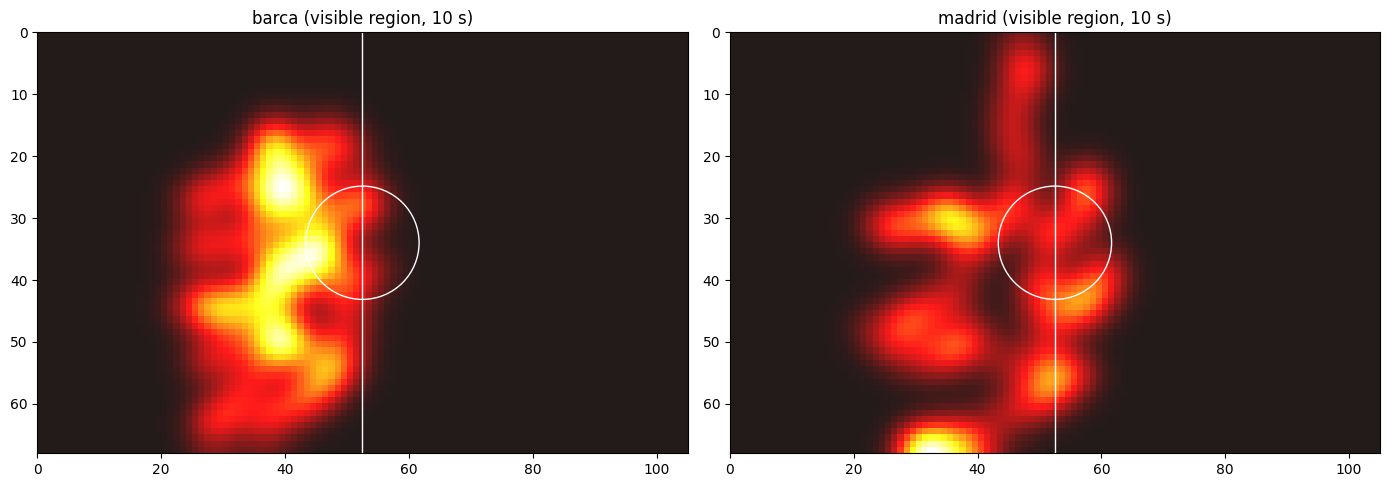

In [56]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def team_heat(team):
    pts = np.vstack([s["xy"] for s in stats.values() if s["team"] == team])
    heat, _, _ = np.histogram2d(pts[:, 0], pts[:, 1], bins=[105, 68], range=[[0, 105], [0, 68]])
    return gaussian_filter(heat, 3)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, team in zip(axs, ["barca", "madrid"]):
    ax.imshow(team_heat(team).T, origin="upper", extent=[0, 105, 68, 0], cmap="hot", alpha=0.9)
    ax.plot([52.5, 52.5], [0, 68], "w-", lw=1)
    ax.add_patch(plt.Circle((52.5, 34), 9.15, fill=False, color="w", lw=1))
    ax.set_title(f"{team} (visible region, 10 s)")
    ax.set_xlim(0, 105); ax.set_ylim(68, 0)
plt.tight_layout()
plt.savefig("/content/heatmaps.png", dpi=120)
plt.show()

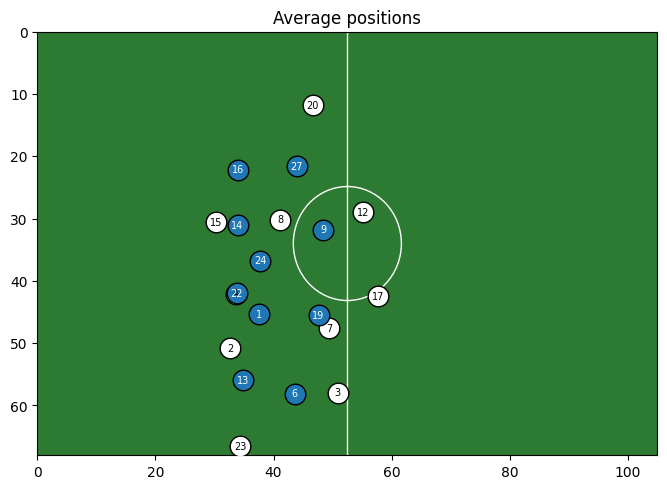

In [57]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.set_facecolor("#2d7a32")
ax.plot([52.5, 52.5], [0, 68], "w-", lw=1)
ax.add_patch(plt.Circle((52.5, 34), 9.15, fill=False, color="w", lw=1))
for pid, s in stats.items():
    mx, my = s["xy"].mean(axis=0)
    c = "tab:blue" if s["team"] == "barca" else "white"
    ax.scatter(mx, my, s=220, c=c, edgecolors="k", zorder=3)
    ax.text(mx, my, str(pid), ha="center", va="center", fontsize=7, zorder=4,
            color="white" if s["team"] == "barca" else "black")
ax.set_xlim(0, 105); ax.set_ylim(68, 0)
ax.set_title("Average positions")
plt.savefig("/content/avg_positions.png", dpi=120)
plt.show()

In [58]:
import pandas as pd

df = pd.DataFrame([
    dict(player_id=pid, team=s["team"], seconds_visible=round(s["seconds"], 1),
         distance_m=round(s["dist"], 1), top_speed_kmh=round(s["top"], 1))
    for pid, s in stats.items()
]).sort_values(["team", "player_id"])

df.to_csv("/content/player_stats.csv", index=False)
print(df.groupby("team")[["distance_m", "top_speed_kmh"]].mean().round(1))

        distance_m  top_speed_kmh
team                             
barca         23.9           12.7
madrid        18.1           10.4


In [59]:
def draw_minimap2(f):
    img = np.zeros((68 * S + 60, 105 * S, 3), np.uint8)
    img[:] = (50, 110, 40)
    off = 30
    cv2.rectangle(img, (0, off), (105 * S - 1, off + 68 * S), (255, 255, 255), 2)
    cv2.line(img, (int(52.5 * S), off), (int(52.5 * S), off + 68 * S), (255, 255, 255), 2)
    cv2.circle(img, (int(52.5 * S), off + 34 * S), int(9.15 * S), (255, 255, 255), 2)
    for tid, b in tracks[f]:
        r = root(tid)
        if r not in final_team:
            continue
        foot = np.array([[[(b[0] + b[2]) / 2, b[3]]]], np.float32)
        px, py = cv2.perspectiveTransform(foot, Hs[f])[0, 0]
        x, y = int(px * S), int(py * S) + off
        if 0 <= x < img.shape[1] and 0 <= y < img.shape[0]:
            cv2.circle(img, (x, y), 6, colors[final_team[r]], -1)
            cv2.putText(img, str(r), (x + 7, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1)
    return img

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, START)
mm = draw_minimap2(0)
out = cv2.VideoWriter("/content/demo_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 30, (832 + mm.shape[1], mm.shape[0]))

for f in range(len(Hs)):
    ok, frame = cap.read()
    if not ok:
        break
    for tid, b in tracks[f]:
        r = root(tid)
        if r not in final_team:
            continue
        x1, y1, x2, y2 = map(int, b)
        col = colors[final_team[r]]
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
        cv2.putText(frame, str(r), (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.8, col, 2)
    left = cv2.resize(frame, (832, mm.shape[0]))
    out.write(np.hstack([left, draw_minimap2(f)]))
out.release()

!ffmpeg -y -i /content/demo_raw.mp4 -c:v libx264 -pix_fmt yuv420p /content/demo.mp4 -loglevel error
!ffmpeg -y -i /content/demo.mp4 -vf "fps=10,scale=800:-1" /content/demo.gif -loglevel error
print("Saved demo.mp4 and demo.gif")

Saved demo.mp4 and demo.gif
